/var/folders/fv/19nygrx97gjfc62f5sl03gx40000gn/T/ipykernel_45245/1942619085.py:22: UserWarning: linewidths is ignored by contourf
  plt.contourf(y1, y2, Z, levels=50, linewidths=0.5)


Text(0, 0.5, 'y2')

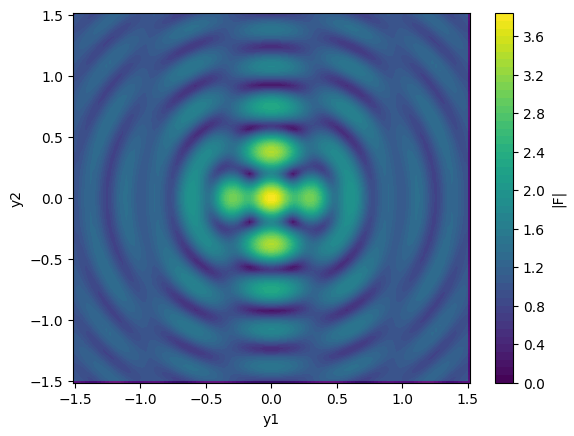

In [21]:
import numpy as np
import time
from gwlens import solver2d
from matplotlib.colors import LogNorm
import matplotlib.pyplot as plt
lens = solver2d.point_mass(0.5, (-0.5, 0.0)) + solver2d.point_mass(0.5, (0.5, 0.0)) 
    # equal-mass binary
y = (0.1, 0.2)
#ws = np.linspace(0.5, 300, 1000)
ws = 10
t = time.perf_counter()
y1 = np.linspace(-1.5, 1.5, 100)
y2 = np.linspace(-1.5, 1.5, 100)
Z = np.empty((len(y2), len(y1)))          # note: rows are y2, columns are y1

for j, b in enumerate(y2):
    for i, a in enumerate(y1):
        F = solver2d.amplification(ws, (a, b), lens)
        Z[j, i] = np.abs(F)            # iw = index of your chosen w

plt.pcolormesh(y1, y2, Z, cmap='magma')
plt.contourf(y1, y2, Z, levels=50, linewidths=0.5)
plt.colorbar(label='|F|')
plt.xlabel('y1')
plt.ylabel('y2')


SIE (q=0.7) + external shear         analytic check 5.1e-10 | 1000 frequencies, |F| from 1.078 to 7.183 | self-check worst 3.5e-13 | 6.8 s incl. self-check
pseudo-elliptical NFW                analytic check 6.1e-10 | 1000 frequencies, |F| from 0.557 to 3.053 | self-check worst 3.4e-13 | 0.2 s incl. self-check
cored halo + 3 point-mass subhalos   analytic check 5.4e-10 | 1000 frequencies, |F| from 0.085 to 3.772 | self-check worst 9.0e-12 | 0.4 s incl. self-check


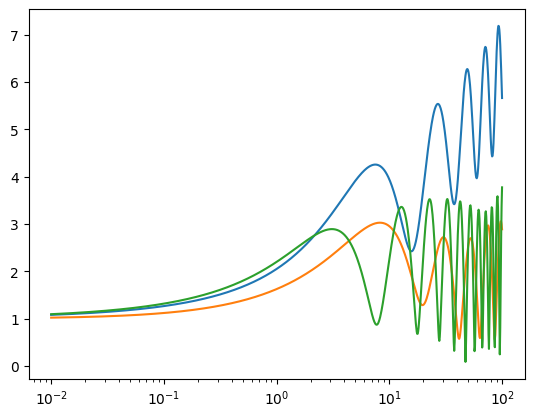

In [ ]:
"""
Defining your own lens for lens2d_general.py: three worked examples.

Recipe
  1. write psi(x1, x2) with analytic numpy operations (it is also called with complex arrays)
  2. list the points where psi is not smooth (point masses, cusps, very small cores)
  3. lens = G.Lens(psi, singular=[...])            # optional: q_inf = kappa + |gamma|
  4. F = G.amplification_many(ws, y, lens)          # or G.amplification(w, y, lens)
     F, err = G.amplification_many(ws, y, lens, estimate_error=True)   # self-check
"""
import time
import numpy as np
from gwlens import solver2d
import matplotlib.pyplot as plt


# ---------------------------------------------------------------- 1. SIE + external shear
def sie_plus_shear(b=1.0, q=0.7, phi=0.3, gamma1=0.05, gamma2=-0.03, x0=(0.0, 0.0)):
    """Singular isothermal ellipsoid (Keeton & Kochanek form) rotated by phi, plus external shear."""
    c, s, sq = np.cos(phi), np.sin(phi), np.sqrt(1 - q * q)
    a1, a2 = x0

    def psi(x1, x2):
        u = c * (x1 - a1) + s * (x2 - a2)                 # coordinates along the ellipse axes
        v = -s * (x1 - a1) + c * (x2 - a2)
        om = np.sqrt(q * q * u * u + v * v)
        ax = b * q / sq * np.arctan(sq * u / om)
        ay = b * q / sq * np.arctanh(sq * v / om)
        return u * ax + v * ay + 0.5 * (gamma1 * (x1 * x1 - x2 * x2) + 2 * gamma2 * x1 * x2)
    return solver2d.Lens(psi, singular=[x0], q_inf=np.hypot(gamma1, gamma2))


# ---------------------------------------------------------------- 2. pseudo-elliptical NFW
def elliptical_nfw(k=2.0, psi0=1.0, e=0.15):
    """NFW potential evaluated at an elliptical radius (pseudo-elliptical NFW)."""
    def psi(x1, x2):
        R = np.sqrt((1 - e) * x1 * x1 + (1 + e) * x2 * x2 + 0j)
        v = k * R
        return 0.5 * psi0 * (np.log(v / 2)**2 + np.arccos(1 / v)**2)
    return solver2d.Lens(psi, singular=[(0.0, 0.0)])


# ---------------------------------------------------------------- 3. host halo + subhalos (built from components)
def host_with_subhalos():
    host = solver2d.cis(psi0=1.0, rc=0.1)
    subs = [(0.01, (1.2, 0.3)), (0.005, (-0.8, 0.9)), (0.02, (0.4, -1.1))]
    lens = host
    for m, pos in subs:
        lens = lens + solver2d.point_mass(m, pos)
    return lens


if __name__ == "__main__":
    ws = np.logspace(-2, 2, 1000)
    for name, lens, y in (("SIE (q=0.7) + external shear", sie_plus_shear(), (0.15, 0.1)),
                          ("pseudo-elliptical NFW", elliptical_nfw(), (0.2, 0.1)),
                          ("cored halo + 3 point-mass subhalos", host_with_subhalos(), (0.3, 0.2))):
        mism = lens.check_analytic()
        t = time.perf_counter()
        F, err = solver2d.amplification_many(ws, y, lens, estimate_error=True)
        dt = time.perf_counter() - t
        print(f"{name:<36} analytic check {mism:.1e} | {ws.size} frequencies, |F| from {abs(F).min():.3f} to {abs(F).max():.3f}"
              f" | self-check worst {err.max():.1e} | {dt:.1f} s incl. self-check", flush=True)
        plt.semilogx(ws,np.abs(F),label=f"{}")
        plt.legend()

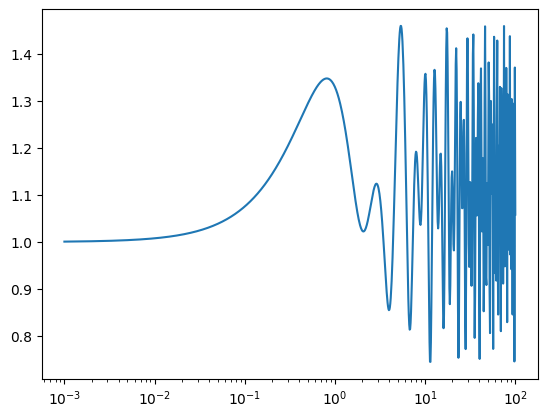

In [37]:
w = np.logspace(-3, 2, 1000)
lens = solver2d.point_mass(0.5, (-0.5, 0.0)) + solver2d.point_mass(0.5, (0.5, 0.0))  

lens_cis = solver2d.cis() + solver2d.cis()
plt.semilogx(w, np.abs(solver2d.amplification_many(w, (1.1, 0.2), lens)), label="binary point masses")


many w : 5000 frequencies at one y          0.07 s
many y : 40000 source positions at one w    0.06 s
sampler: one solver, 3 new y x 5000 frequencies    0.14 s


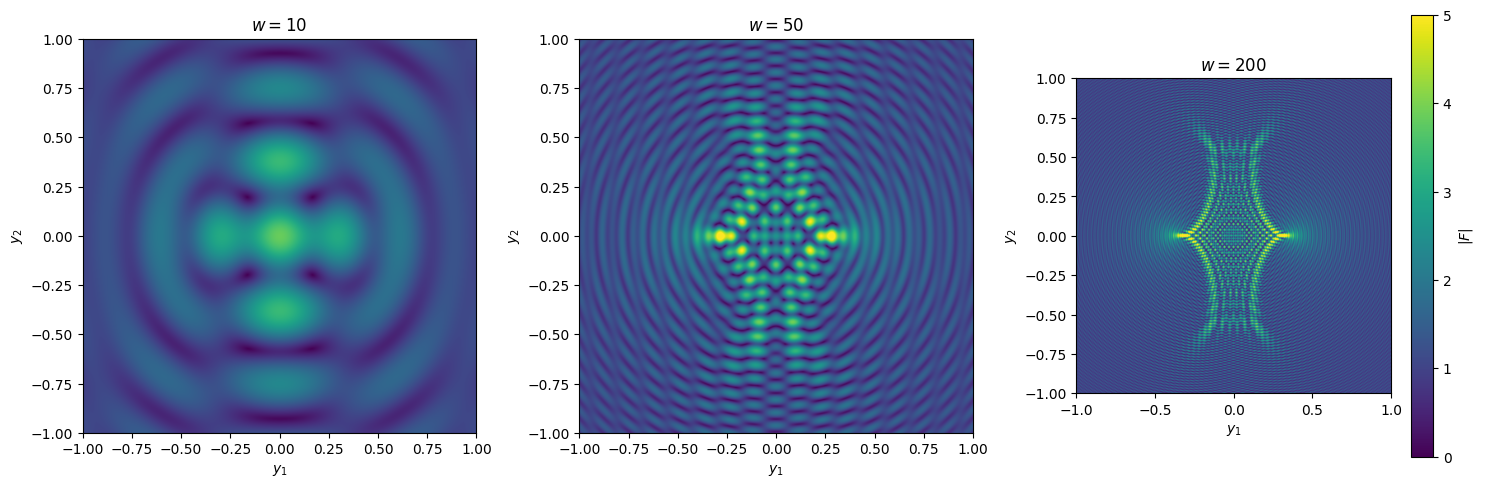

In [38]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-1.0, 1.0, 1000)
Y1, Y2 = np.meshgrid(x, x)

w_values = [10, 50, 200]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Use the same color scale for every subplot
vmin, vmax = 0, 5

for ax, w in zip(axes, w_values):
    Fm = solver2d.amplification_map(w, Y1, Y2, lens)

    im = ax.imshow(
        np.abs(Fm),
        extent=(-1, 1, -1, 1),
        origin="lower",
        cmap="viridis",
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(f"$w={w}$")
    ax.set_xlabel("$y_1$")
    ax.set_ylabel("$y_2$")



plt.colorbar(im,  label="$|F|$")

plt.tight_layout()
plt.savefig(fname="binary_map.png",dpi=300)

#plt.show()

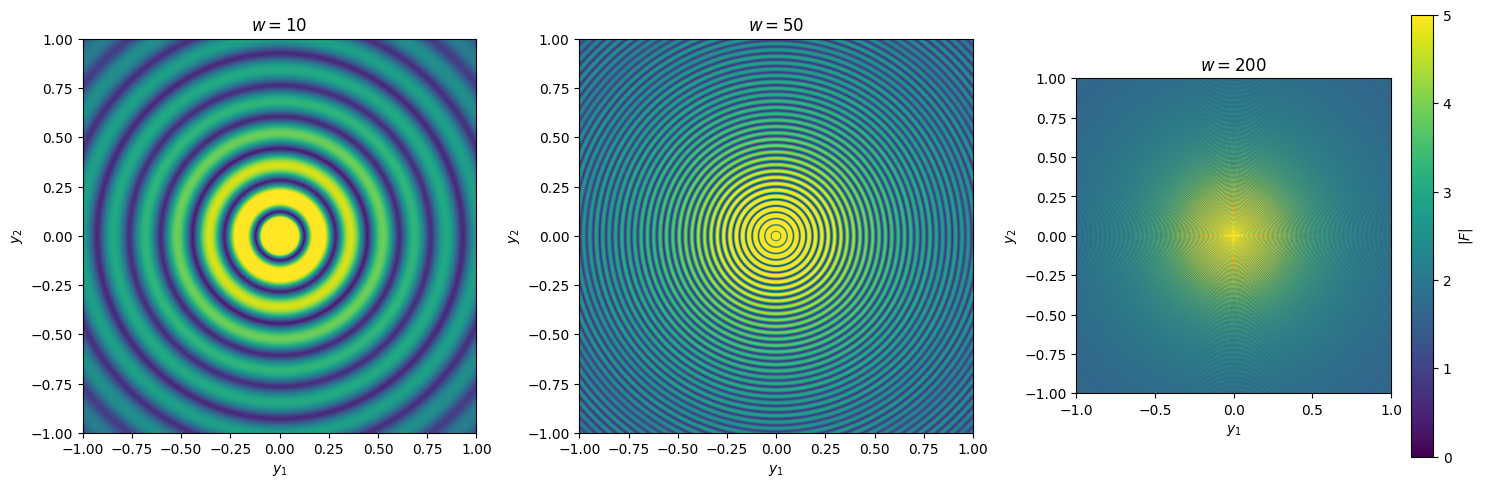

In [34]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-1.0, 1.0, 1000)
Y1, Y2 = np.meshgrid(x, x)

w_values = [10, 50, 200]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Use the same color scale for every subplot
vmin, vmax = 0, 5

for ax, w in zip(axes, w_values):
    Fm = solver2d.amplification_map(w, Y1, Y2, lens_cis)

    im = ax.imshow(
        np.abs(Fm),
        extent=(-1, 1, -1, 1),
        origin="lower",
        cmap="viridis",
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(f"$w={w}$")
    ax.set_xlabel("$y_1$")
    ax.set_ylabel("$y_2$")



plt.colorbar(im,  label="$|F|$")

plt.tight_layout()
plt.savefig(fname="cis_map.png",dpi=300)

#plt.show()

In [10]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-1, 1, 500)
Y1, Y2 = np.meshgrid(x, x)

# Six values of w
w_values = [4,20,100] #np.logspace(1, 2, 6)
off = 2.0
#lens = point_mass(0.25, (-0.5, 0.0)) + point_mass(0.25, (0.5, 0.0))+ point_mass(0.25, (0.0, 0.5)) + point_mass(0.25, (0.0, -0.5))
lens = cis(psi0=1.0, rc=0.05, x0=(off, 0.0))+cis(psi0=1.0, rc=0.05, x0=(-off, 0))+cis(psi0=1.0, rc=0.05, x0=(0, off))+cis(psi0=1.0, rc=0.05, x0=(0.0, -off))
# Create 2 rows and 3 columns
fig, axes = plt.subplots(1, 3, figsize=(15, 9))

for ax, w in zip(axes.flat, w_values):

    F = np.abs(amplification_map(w, Y1, Y2, lens))

    im = ax.imshow(
        F,
        extent=(-1, 1, -1, 1),
        cmap='inferno'
    )

    ax.set_title(f'$w = {w:.3g}$')
    ax.set_xlabel('$y_1$')
    ax.set_ylabel('$y_2$')

    fig.colorbar(im, ax=ax, label='$|F|$')

plt.tight_layout()
plt.suptitle('CIS')
plt.show()

NameError: name 'cis' is not defined

Text(0, 0.5, '|F|')

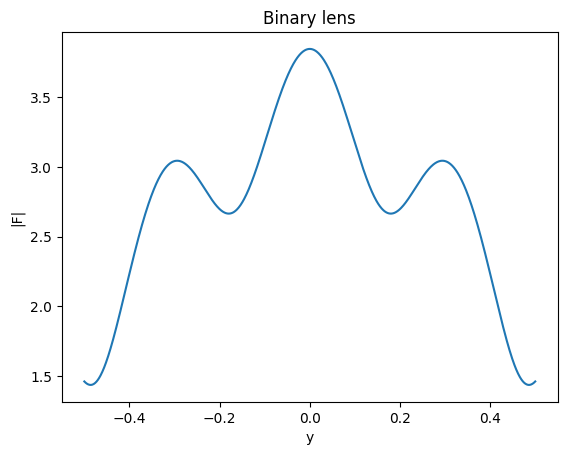

In [4]:
import matplotlib.pyplot as plt
w_val = np.linspace(0.1, 100, 1000)
y_val = np.linspace(-0.5, 0.5, 1000)
lens1  = point_mass(0.5, (-0.5, 0.0)) + point_mass(0.5, (0.5, 0.0))
F_val = []
for i in y_val:
    F_val.append(amplification(10, (i,0), lens1))
plt.plot(y_val, np.abs(F_val))
plt.title('Binary lens')
plt.xlabel('y')
plt.ylabel('|F|')

Time taken for amplification_many: 0.11 seconds


Text(0, 0.5, '|F|')

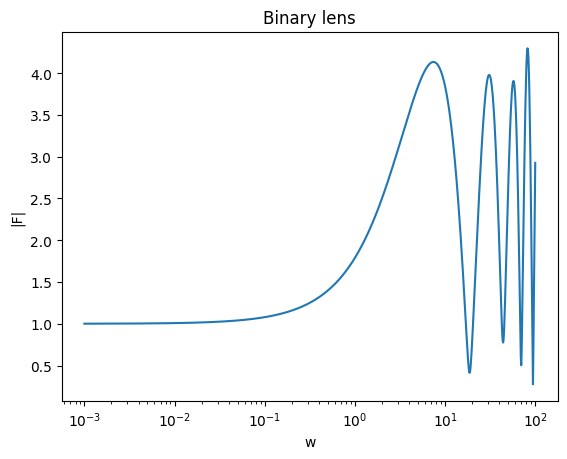

In [20]:
import time
w_val = np.logspace(-3, 2, 1000)
off =0.1
#lens = cis(psi0=1.0, rc=0.05, x0=(off, 0.0))+cis(psi0=1.0, rc=0.05, x0=(-off, 0))+cis(psi0=1.0, rc=0.05, x0=(0, off))+cis(psi0=1.0, rc=0.05, x0=(0.0, -off))
lens= point_mass(0.5, (-0.5, 0.0)) + point_mass(0.5, (0.5, 0.0))
start_time = time.time()
F = amplification_many(w_val, (0.0, 0.0), lens,n_workers=3)
end_time = time.time()
print(f"Time taken for amplification_many: {end_time - start_time:.2f} seconds")
plt.semilogx(w_val, np.abs(F))
plt.title('Binary lens')
plt.xlabel('w')
plt.ylabel('|F|')   
